In [40]:
# MNIST Veri Seti ile MLP Tabanlı El Yazısı Rakam Tanıma

In [41]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

In [42]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

full_train_dataset = datasets.MNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

In [43]:
generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset = random_split(full_train_dataset, [50000, 10000], generator=generator)

train_loader = DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(dataset=val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(dataset=test_dataset, batch_size=64, shuffle=False)


In [ ]:
print(f"Train veri sayısı: {len(train_dataset)}")
print(f"Validation veri sayısı: {len(val_dataset)}")
print(f"Test veri sayısı: {len(test_dataset)}")

In [44]:
import torch.nn as nn

class MLP(nn.Module):
  def __init__(self):
    super().__init__()
    self.flatten = nn.Flatten()

    self.fc1 = nn.Linear(in_features=784, out_features=128)

    self.fc2 = nn.Linear(in_features=128, out_features=64)

    self.fc3 = nn.Linear(in_features=64, out_features=10)

    self.relu = nn.ReLU()

  def forward(self, x):
    x = self.flatten(x)

    x = self.fc1(x)
    x = self.relu(x)

    x = self.fc2(x)
    x = self.relu(x)

    out = self.fc3(x)

    return out

In [45]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Kullanılan donanım:", device)

model = MLP().to(device)
print(model)


images, labels = next(iter(train_loader))

sample_outputs = model(images.to(device))
print("Model girdi boyutu:", images.shape)
print("Model çıktı boyutu:", sample_outputs.shape)

Kullanılan donanım: cpu
MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=10, bias=True)
  (relu): ReLU()
)
Model girdi boyutu: torch.Size([64, 1, 28, 28])
Model çıktı boyutu: torch.Size([64, 10])


In [46]:
import time
import torch.optim as optim

epochs = 15
learning_rate = 0.001

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(model.parameters(), lr=learning_rate)

In [47]:
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

start_time = time.time()

print("Eğitim başlıyor...\n" + "-" * 65)

for epoch in range(epochs):
    # --- EĞİTİM (TRAINING) ---
    model.train()
    running_train_loss = 0.0
    correct_train = 0
    total_train = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        correct_train += (predictions == labels).sum().item()
        total_train += labels.size(0)

    epoch_train_loss = running_train_loss / total_train
    epoch_train_acc = (correct_train / total_train) * 100

    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_acc)

    # --- DOĞRULAMA (VALIDATION) ---
    model.eval()
    running_val_loss = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            correct_val += (predictions == labels).sum().item()
            total_val += labels.size(0)

    epoch_val_loss = running_val_loss / total_val
    epoch_val_acc = (correct_val / total_val) * 100

    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_acc)

    print(f"Epoch [{epoch+1:2d}/{epochs}] | "
          f"Train Loss: {epoch_train_loss:.4f}, Train Acc: %{epoch_train_acc:.2f} | "
          f"Val Loss: {epoch_val_loss:.4f}, Val Acc: %{epoch_val_acc:.2f}")

total_training_time = time.time() - start_time
print("-" * 65)
print(f"Eğitim tamamlandı. Toplam Eğitim Süresi: {total_training_time:.2f} saniye")

Eğitim başlıyor...
-----------------------------------------------------------------
Epoch [ 1/15] | Train Loss: 0.3003, Train Acc: %91.21 | Val Loss: 0.1615, Val Acc: %95.11
Epoch [ 2/15] | Train Loss: 0.1260, Train Acc: %96.24 | Val Loss: 0.1302, Val Acc: %95.99
Epoch [ 3/15] | Train Loss: 0.0885, Train Acc: %97.25 | Val Loss: 0.1215, Val Acc: %96.32
Epoch [ 4/15] | Train Loss: 0.0696, Train Acc: %97.79 | Val Loss: 0.1046, Val Acc: %96.88
Epoch [ 5/15] | Train Loss: 0.0545, Train Acc: %98.27 | Val Loss: 0.1101, Val Acc: %96.81
Epoch [ 6/15] | Train Loss: 0.0447, Train Acc: %98.54 | Val Loss: 0.1364, Val Acc: %96.17
Epoch [ 7/15] | Train Loss: 0.0374, Train Acc: %98.76 | Val Loss: 0.1096, Val Acc: %96.95
Epoch [ 8/15] | Train Loss: 0.0310, Train Acc: %98.99 | Val Loss: 0.1030, Val Acc: %97.28
Epoch [ 9/15] | Train Loss: 0.0287, Train Acc: %98.99 | Val Loss: 0.1083, Val Acc: %97.28
Epoch [10/15] | Train Loss: 0.0247, Train Acc: %99.19 | Val Loss: 0.1022, Val Acc: %97.42
Epoch [11/15] |

In [48]:
model.eval()
running_test_loss = 0.0
correct_test = 0
total_test = 0

with torch.no_grad():
  for images, labels in test_loader:
      images, labels = images.to(device), labels.to(device)

      outputs = model(images)
      loss = criterion(outputs, labels)

      running_test_loss += loss.item() * images.size(0)
      predictions = outputs.argmax(dim=1)
      correct_test += (predictions == labels).sum().item()
      total_test += labels.size(0)

test_loss = running_test_loss / total_test
test_acc = (correct_test / total_test) * 100

print(f"Test Loss: {test_loss:.4f} | Test Accuracy: %{test_acc:.2f} ({correct_test}/{total_test})")

Test Loss: 0.1003 | Test Accuracy: %97.86 (9786/10000)


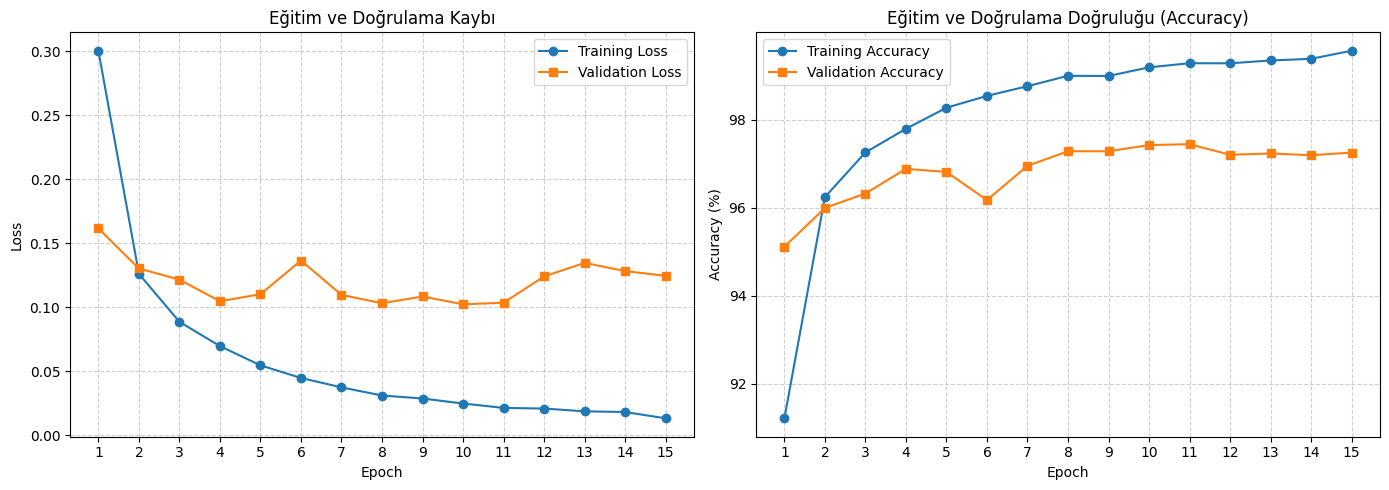

In [49]:
import matplotlib.pyplot as plt

epoch_range = range(1, epochs+1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epoch_range, train_losses, label='Training Loss', marker='o')
plt.plot(epoch_range, val_losses, label='Validation Loss', marker='s')
plt.title('Eğitim ve Doğrulama Kaybı')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(epoch_range)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epoch_range, train_accuracies, label='Training Accuracy', marker='o')
plt.plot(epoch_range, val_accuracies, label='Validation Accuracy', marker='s')
plt.title('Eğitim ve Doğrulama Doğruluğu (Accuracy)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.xticks(epoch_range)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.savefig('deney1_grafikler.png', dpi=300)
plt.show()

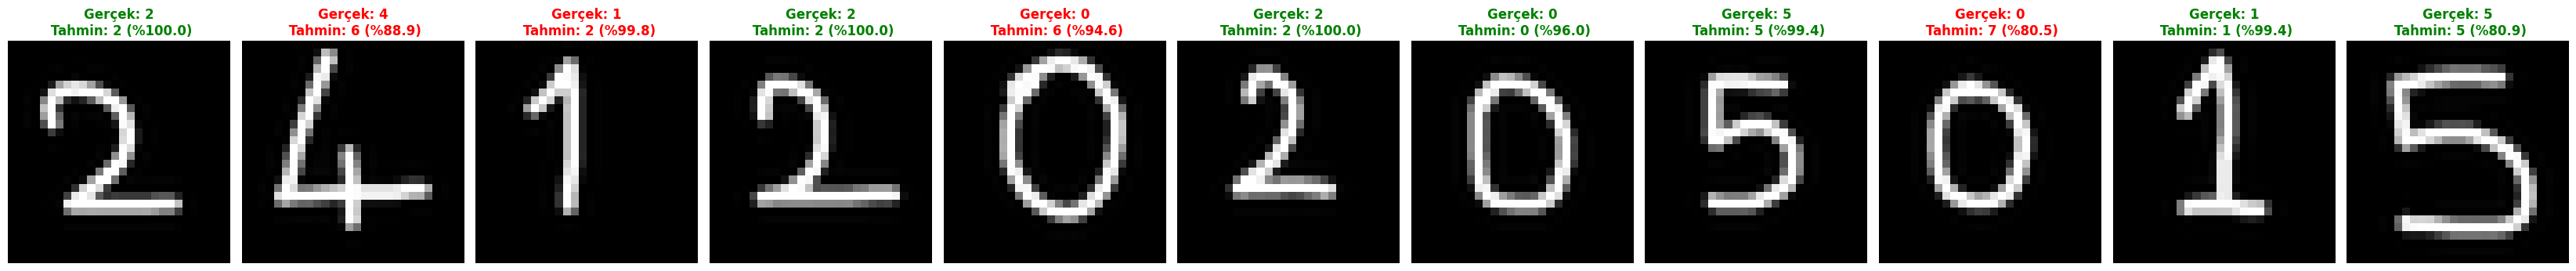

Gerçek Öğrenci Numarası : 24120205015
Modelin Tahmin Ettiği   : 26226205715
Kendi El Yazım Üzerinde Doğruluk: %63.64 (7/11)


In [51]:
from PIL import Image, ImageOps
import torch.nn.functional as F
import numpy as np

torch.save(model.state_dict(), 'mnist_mlp.pth')

image_files = ['num_1.png', 'num_2.png', 'num_3.png', 'num_4.png', 'num_5.png', 'num_6.png', 'num_7.png', 'num_8.png', 'num_9.png', 'num_10.png', 'num_11.png']

true_student_number = [2, 4, 1, 2, 0, 2, 0, 5, 0, 1, 5]

def preprocess_custom_image(image_path):
  img = Image.open(image_path).convert('L')

  img = ImageOps.invert(img)

  img_np = np.array(img)
  img_np = np.where(img_np < 50, 0, np.clip(img_np * 1.5, 0, 255)).astype(np.uint8)
  img = Image.fromarray(img_np)

  img = img.resize((28, 28), Image.Resampling.LANCZOS)

  img_tensor = transform(img).unsqueeze(0).to(device)

  return img, img_tensor

model.eval()
predicted_number = []

plt.figure(figsize=(3 * len(image_files), 4))

for i, file_path in enumerate(image_files):
  processed_pil_img, input_tensor = preprocess_custom_image(file_path)

  with torch.no_grad():
    output = model(input_tensor)
    probabilities = F.softmax(output, dim=1)
    confidence, pred_digit = torch.max(probabilities, dim=1)

    pred_val = pred_digit.item()
    conf_val = confidence.item() * 100
    predicted_number.append(pred_val)

  plt.subplot(1, len(image_files), i+1)
  plt.imshow(processed_pil_img, cmap='gray')

  true_val = true_student_number[i]
  color = 'green' if pred_val == true_val else 'red'

  plt.title(f"Gerçek: {true_val}\n Tahmin: {pred_val} (%{conf_val:.1f})", color=color, fontweight='bold')
  plt.axis('off')

plt.tight_layout()
plt.savefig('ogrenci_numarasi_tahmin.png', dpi=300)
plt.show()

correct_digits = sum(p == t for p, t in zip(predicted_number, true_student_number))
custom_acc = (correct_digits / len(true_student_number)) * 100
print(f"Gerçek Öğrenci Numarası : {''.join(map(str, true_student_number))}")
print(f"Modelin Tahmin Ettiği   : {''.join(map(str, predicted_number))}")
print(f"Kendi El Yazım Üzerinde Doğruluk: %{custom_acc:.2f} ({correct_digits}/{len(true_student_number)})")
